# Tickia: evidencia ejecutada de MySQL y análisis con Pandas

Proyecto de Programación Avanzada. Todas las salidas se obtienen al ejecutar el código. Las operaciones comerciales de demostración usan una base aislada. El histórico se filtra con origen = dataset. No se muestran credenciales ni contraseñas.

In [1]:
from pathlib import Path
import os, sys, json, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import text
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for ancestor in candidates for p in (ancestor, ancestor / 'codigo_fuente')
            if (p / 'Pagina Web' / 'backend' / 'academic').is_dir())
sys.path.insert(0, str(ROOT / 'Pagina Web'))
# El ZIP usa una instancia propia en 3308; reutiliza su configuración local sin mostrarla.
delivery = ROOT.parent / '.entrega_config'
if ROOT.name == 'codigo_fuente' and not os.getenv('TICKIA_ACADEMIC_MYSQL_URL') and (delivery / 'mysql.env').is_file():
    from sqlalchemy.engine import URL
    values = dict(line.split('=', 1) for line in (delivery / 'mysql.env').read_text(encoding='utf-8').splitlines() if '=' in line)
    ports = json.loads((delivery / 'puertos.json').read_text(encoding='utf-8'))
    os.environ['TICKIA_ACADEMIC_MYSQL_URL'] = URL.create('mysql+pymysql', username=values['MYSQL_USER'],
        password=values['MYSQL_PASSWORD'], host='127.0.0.1', port=ports['mysql'], database=values['MYSQL_DATABASE'],
        query={'charset':'utf8mb4'}).render_as_string(hide_password=False)
    os.environ['TICKIA_LOCAL_DIR'] = str(delivery / 'app')
from backend.academic.database import engine
from backend.academic.analytics import build_bundle, sql_queries, export_csv, load_frames
from backend.academic.analysis_frames import clean_shipments
OUTPUT = Path(os.getenv('TICKIA_REPORT_OUTPUT', ROOT / 'Proyecto_PrograAvanzada/.local/analisis_informe'))
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':130, 'savefig.dpi':200})
print('Python:', platform.python_version(), '| Pandas:', pd.__version__, '| NumPy:', np.__version__)
with engine.connect() as connection:
    print('MySQL:', connection.execute(text('SELECT VERSION()')).scalar_one())

Python: 3.13.12 | Pandas: 3.1.1 | NumPy: 2.5.0
MySQL: 8.4.13


## 1. Base cargada y estructura normalizada
Se cuentan las tablas base por separado de las vistas. Los tres usuarios operativos y los registros web son ficticios y se incluyen en el respaldo de entrega.

In [2]:
with engine.connect() as connection:
    tables = pd.read_sql_query(text("SELECT TABLE_NAME tabla FROM information_schema.TABLES WHERE TABLE_SCHEMA=DATABASE() AND TABLE_TYPE='BASE TABLE' ORDER BY TABLE_NAME"), connection)
    counts = []
    for name in tables.tabla:
        amount = connection.execute(text('SELECT COUNT(*) FROM `' + name + '`')).scalar_one()
        counts.append({'tabla':name, 'filas':amount})
    counts = pd.DataFrame(counts)
display(counts)
print('Tablas base:', len(counts), '| Filas físicas:', int(counts.filas.sum()))
counts.to_csv(OUTPUT / 'conteos_bd.csv', index=False)

,tabla,filas
0,categorias,110
1,couriers,8
2,cupones,350
3,departamentos,23
4,distritos,65
5,envios,98077
6,favoritos,79971
7,pagos,111529
8,pedido_detalle,247485
9,pedidos,111017


Tablas base: 17 | Filas físicas: 801586


In [3]:
sql_fk = """SELECT TABLE_NAME tabla, COLUMN_NAME columna,
    REFERENCED_TABLE_NAME referencia, REFERENCED_COLUMN_NAME clave_destino
FROM information_schema.KEY_COLUMN_USAGE
WHERE TABLE_SCHEMA=DATABASE() AND REFERENCED_TABLE_NAME IS NOT NULL
ORDER BY TABLE_NAME, COLUMN_NAME"""
with engine.connect() as connection:
    foreign_keys = pd.read_sql_query(text(sql_fk), connection)
display(foreign_keys)
print('Llaves foráneas:', len(foreign_keys))
foreign_keys.to_csv(OUTPUT / 'llaves_foraneas.csv', index=False)

,tabla,columna,referencia,clave_destino
0,categorias,id_padre,categorias,id_categoria
1,distritos,id_provincia,provincias,id_provincia
2,envios,id_courier,couriers,id_courier
3,envios,id_pedido,pedidos,id_pedido
4,favoritos,id_producto,productos,id_producto
5,favoritos,id_usuario,usuarios,id_usuario
6,pagos,id_pedido,pedidos,id_pedido
7,pedido_detalle,id_pedido,pedidos,id_pedido
8,pedido_detalle,id_variante,variantes,id_variante
9,pedidos,id_cupon,cupones,id_cupon


Llaves foráneas: 22


In [4]:
with engine.connect() as connection:
    views = pd.read_sql_query(text('SELECT TABLE_NAME vista FROM information_schema.VIEWS WHERE TABLE_SCHEMA=DATABASE()'), connection)
    procedures = pd.read_sql_query(text("SELECT ROUTINE_NAME procedimiento, ROUTINE_COMMENT version FROM information_schema.ROUTINES WHERE ROUTINE_SCHEMA=DATABASE() AND ROUTINE_TYPE='PROCEDURE'"), connection)
    triggers = pd.read_sql_query(text('SELECT TRIGGER_NAME nombre, ACTION_TIMING momento, EVENT_MANIPULATION evento, EVENT_OBJECT_TABLE tabla FROM information_schema.TRIGGERS WHERE TRIGGER_SCHEMA=DATABASE()'), connection)
display(views); display(procedures); display(triggers)

,vista
0,v_distritos
1,v_pedidos_importes
2,v_ventas_vendedor


,procedimiento,version
0,confirmar_pedido,tickia-universidad-v3


,nombre,momento,evento,tabla
0,tr_pedido_validar_estado,BEFORE,UPDATE,pedidos


## 2. Consultas SQL ejecutadas
El archivo de consultas contiene 13 sentencias identificadas. Aquí se muestran resultados, ventanas y el uso real de índices.

In [5]:
queries = sql_queries()
print(queries['ranking_vendedores'])
with engine.connect() as connection:
    ranking = pd.read_sql_query(text(queries['ranking_vendedores']), connection)
display(ranking.head(8))
print('Vendedores con ventas válidas:', len(ranking))

-- RANK conserva empates. ROWS y el ID resuelven el orden del acumulado.
SELECT id_vendedor,razon_social,pedidos,ventas_brutas,
  RANK() OVER(ORDER BY ventas_brutas DESC) posicion,
  SUM(ventas_brutas) OVER(ORDER BY ventas_brutas DESC,id_vendedor ROWS UNBOUNDED PRECEDING) ventas_acumuladas
FROM v_ventas_vendedor WHERE pedidos>0
ORDER BY ventas_brutas DESC,id_vendedor


,id_vendedor,razon_social,pedidos,ventas_brutas,posicion,ventas_acumuladas
0,41,Importaciones Norte S.A.C.,57329,"31,435,935.03",1,"31,435,935.03"
1,282,Inversiones Sol E.I.R.L. 281,6552,"14,741,775.67",2,"46,177,710.70"
2,58,Grupo Rímac S.A.C. 57,660,"2,021,369.35",3,"48,199,080.05"
3,606,Corporación del Sur E.I.R.L.,628,"1,216,481.44",4,"49,415,561.49"
4,386,Negocios Titicaca S.A.C.,3687,"1,206,974.27",5,"50,622,535.76"
5,509,Negocios Norte S.R.L. 508,3828,"1,126,847.20",6,"51,749,382.96"
6,485,Negocios Titicaca S.R.L.,598,"879,734.30",7,"52,629,117.26"
7,507,Corporación Andina E.I.R.L. 506,316,"795,249.03",8,"53,424,366.29"


Vendedores con ventas válidas: 676


In [6]:
print(queries['ventas_mensuales'])
with engine.connect() as connection:
    monthly = pd.read_sql_query(text(queries['ventas_mensuales']), connection)
display(monthly.head(8))
print('Observaciones vendedor-mes:', len(monthly))

-- LAG compara con el mes observado anterior del mismo vendedor.
WITH meses AS (
  SELECT p.id_vendedor,DATE_FORMAT(pe.fecha,'%Y-%m') mes,SUM(de.cantidad*de.precio_unit) ventas_brutas
  FROM pedidos pe JOIN pedido_detalle de USING(id_pedido)
  JOIN variantes va USING(id_variante) JOIN productos p USING(id_producto)
  WHERE pe.origen='dataset' AND pe.estado IN ('pagado','enviado','entregado')
  GROUP BY p.id_vendedor,DATE_FORMAT(pe.fecha,'%Y-%m')
)
SELECT id_vendedor,mes,ventas_brutas,
  LAG(ventas_brutas) OVER(PARTITION BY id_vendedor ORDER BY mes) ventas_mes_anterior,
  SUM(ventas_brutas) OVER(PARTITION BY id_vendedor ORDER BY mes ROWS UNBOUNDED PRECEDING) acumulado_vendedor
FROM meses ORDER BY id_vendedor,mes


,id_vendedor,mes,ventas_brutas,ventas_mes_anterior,acumulado_vendedor
0,1,2025-04,72.00,NaN,72.00
1,1,2025-07,"1,313.80",72.00,"1,385.80"
2,1,2025-09,"1,839.31","1,313.80","3,225.11"
3,1,2025-11,136.80,"1,839.31","3,361.91"
4,1,2025-12,"1,804.51",136.80,"5,166.42"
5,1,2026-02,"1,238.20","1,804.51","6,404.62"
6,1,2026-03,887.90,"1,238.20","7,292.52"
7,1,2026-04,641.90,887.90,"7,934.42"


Observaciones vendedor-mes: 8130


In [7]:
with engine.connect() as connection:
    critical_plan = pd.read_sql_query(text('EXPLAIN SELECT id_variante FROM variantes WHERE stock<=3'), connection)
    orders_plan = pd.read_sql_query(text('EXPLAIN SELECT id_pedido FROM pedidos WHERE id_usuario=1 ORDER BY fecha DESC,id_pedido DESC LIMIT 24'), connection)
display(critical_plan[['table','type','possible_keys','key','rows','Extra']])
display(orders_plan[['table','type','possible_keys','key','rows','Extra']])

,table,type,possible_keys,key,rows,Extra
0,variantes,range,idx_variante_stock,idx_variante_stock,1930,Using where; Using index


,table,type,possible_keys,key,rows,Extra
0,pedidos,ref,"uq_pedido_solicitud,idx_pedido_usuario_fecha",idx_pedido_usuario_fecha,2,Using index


## 3. Análisis con Pandas
Los importes de ventas, las reseñas y los envíos se agregan por separado. Se excluyen pedidos pendientes y cancelados del histórico. El reporte de stock usa inventario actual.

In [8]:
bundle = build_bundle()
reports = bundle['reports']
display(pd.DataFrame([bundle['summary']]))
print('Referencia RFM:', bundle['reference_date'])
for name, frame in reports.items():
    (OUTPUT / (name + '.csv')).write_bytes(export_csv(frame))
metadata = {key:value for key,value in bundle.items() if key not in ('reports','charts')}
(OUTPUT / 'resultados.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Reportes completos exportados:', len(reports))

,clientes,pedidos_analizados,vendedores,resenas,envios_validos,vendedores_detectados
0,45000,98871,700,40071,96288,14


Referencia RFM: 2026-10-01


Reportes completos exportados: 18


In [9]:
rfm = reports['rfm']
segments = rfm.segmento.value_counts().rename_axis('segmento').reset_index(name='clientes')
display(segments)
display(rfm.head(6))

,segmento,clientes
0,Sin compras,20714
1,Ocasionales,10680
2,Campeones,4962
3,Leales,3075
4,En riesgo,2796
5,Nuevos,2773


,id_usuario,recencia_dias,frecuencia,monetario,r,f,m,segmento
849,850,11.00,51,"36,514.65",5,5,5,Campeones
27465,27466,5.00,51,"30,780.22",5,5,5,Campeones
39799,39800,4.00,47,"28,897.86",5,5,5,Campeones
17692,17693,8.00,47,"28,656.21",5,5,5,Campeones
44057,44058,2.00,47,"20,847.35",5,5,5,Campeones
16714,16715,12.00,43,"39,704.27",5,5,5,Campeones


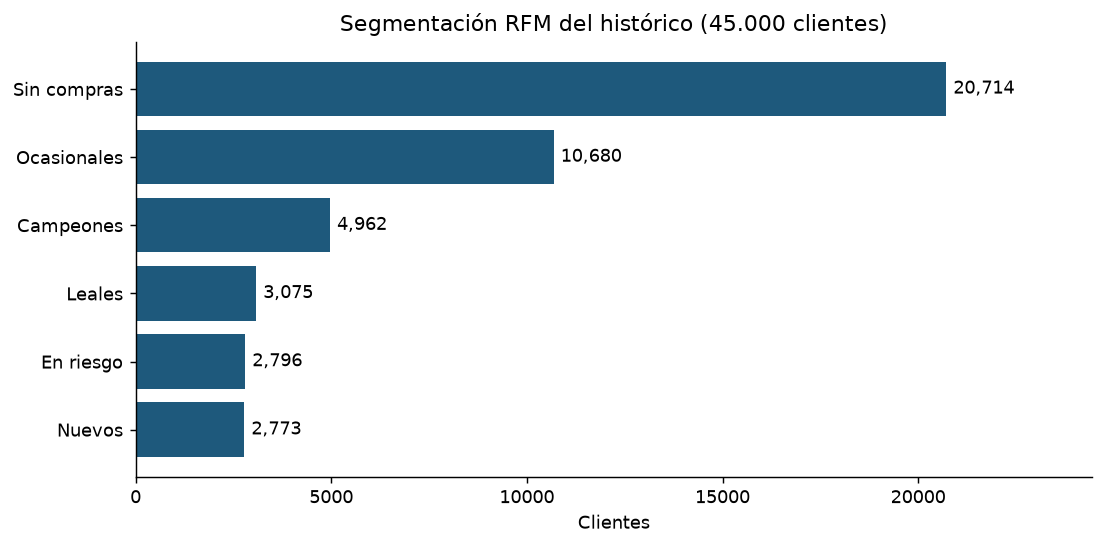

In [10]:
fig, ax = plt.subplots(figsize=(8.6,4.3))
bars = ax.barh(segments.segmento[::-1], segments.clientes[::-1], color='#1E597C')
ax.bar_label(bars, fmt='{:,.0f}', padding=4)
ax.set(xlabel='Clientes', title='Segmentación RFM del histórico (45.000 clientes)')
ax.set_xlim(0, segments.clientes.max()*1.18)
fig.tight_layout(); fig.savefig(OUTPUT/'grafico_rfm.png', bbox_inches='tight'); plt.show()

In [11]:
cohorts = reports['cohortes']
cohort_names = sorted(cohorts.cohorte.unique())[-12:]
matrix = cohorts[cohorts.cohorte.isin(cohort_names)].pivot(index='cohorte', columns='mes', values='retencion_pct').reindex(index=cohort_names, columns=range(12))
display(matrix.round(1))

mes,0,1,2,3,4,5,6,7,8,9,10,11
cohorte,,,,,,,,,,,,
2025-10,100.00,21.80,12.60,12.70,10.80,12.20,11.40,11.50,12.50,11.90,13.00,14.00
2025-11,100.00,23.20,10.10,10.80,12.30,12.50,11.40,14.20,11.50,14.30,11.60,NaN
2025-12,100.00,24.10,11.80,13.30,11.20,13.20,10.70,12.80,12.00,12.70,NaN,NaN
2026-01,100.00,24.60,11.60,11.60,12.20,12.70,14.20,14.40,12.50,NaN,NaN,NaN
2026-02,100.00,29.80,9.40,11.20,12.00,14.80,13.80,10.60,NaN,NaN,NaN,NaN
2026-03,100.00,28.80,11.50,10.20,11.50,14.30,10.70,NaN,NaN,NaN,NaN,NaN
2026-04,100.00,29.60,10.40,11.60,12.80,12.00,NaN,NaN,NaN,NaN,NaN,NaN
2026-05,100.00,32.20,13.80,12.80,12.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-06,100.00,30.30,9.90,13.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


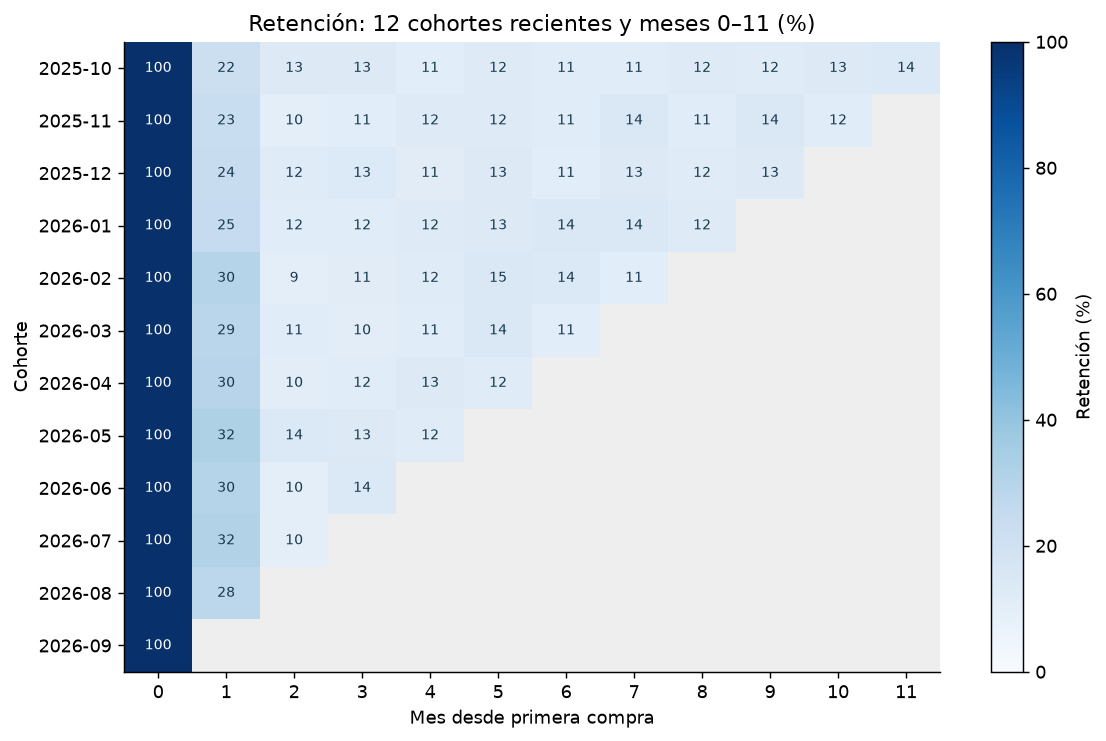

Meses sin exposición: celdas grises; no se convierten en cero.


In [12]:
fig, ax = plt.subplots(figsize=(9,5.8))
colors = plt.get_cmap('Blues').copy(); colors.set_bad('#EEEEEE')
image = ax.imshow(matrix.to_numpy(dtype=float), vmin=0, vmax=100, aspect='auto', cmap=colors)
ax.set_xticks(range(12), labels=range(12)); ax.set_yticks(range(12), labels=cohort_names)
for row_index in range(12):
    for column_index in range(12):
        value = matrix.iloc[row_index,column_index]
        if pd.notna(value): ax.text(column_index,row_index,f'{value:.0f}',ha='center',va='center',fontsize=8,color='white' if value>50 else '#17384E')
ax.set(xlabel='Mes desde primera compra', ylabel='Cohorte', title='Retención: 12 cohortes recientes y meses 0–11 (%)')
fig.colorbar(image, ax=ax, label='Retención (%)')
fig.tight_layout(); fig.savefig(OUTPUT/'grafico_cohortes.png', bbox_inches='tight'); plt.show()
print('Meses sin exposición: celdas grises; no se convierten en cero.')

In [13]:
pairs = reports['cocompras']
display(pairs.head(6))
print('Los productos se deduplican dentro de cada pedido antes de formar parejas.')
top = pairs.head(8).copy()
import textwrap
labels = [textwrap.fill(a+' + '+b, 45) for a,b in zip(top.producto_a,top.producto_b)]

,producto_a,producto_b,pedidos_juntos,soporte_pct,confianza_a_b_pct,lift
235,Coches de bebé Huggies Edición Especial,Biberones Babysec Max,563,0.57,24.50,22.10
330,Peluches Infanti X,Bloques de construcción Mattel Lite,215,0.22,25.84,30.34
565,Calefactores Miray Classic,Lavadoras Bosch Ultra,175,0.18,24.37,70.67
2410,Bloques de construcción Mattel Lite,Juegos de mesa Lego Classic,162,0.16,19.24,31.29
151,Alimento para gato Cat Chow Sport,Pañales Infanti Sport,142,0.14,27.84,97.97
452,Biberones Babysec Max,Cascos Coleman Air,139,0.14,12.68,25.33


Los productos se deduplican dentro de cada pedido antes de formar parejas.


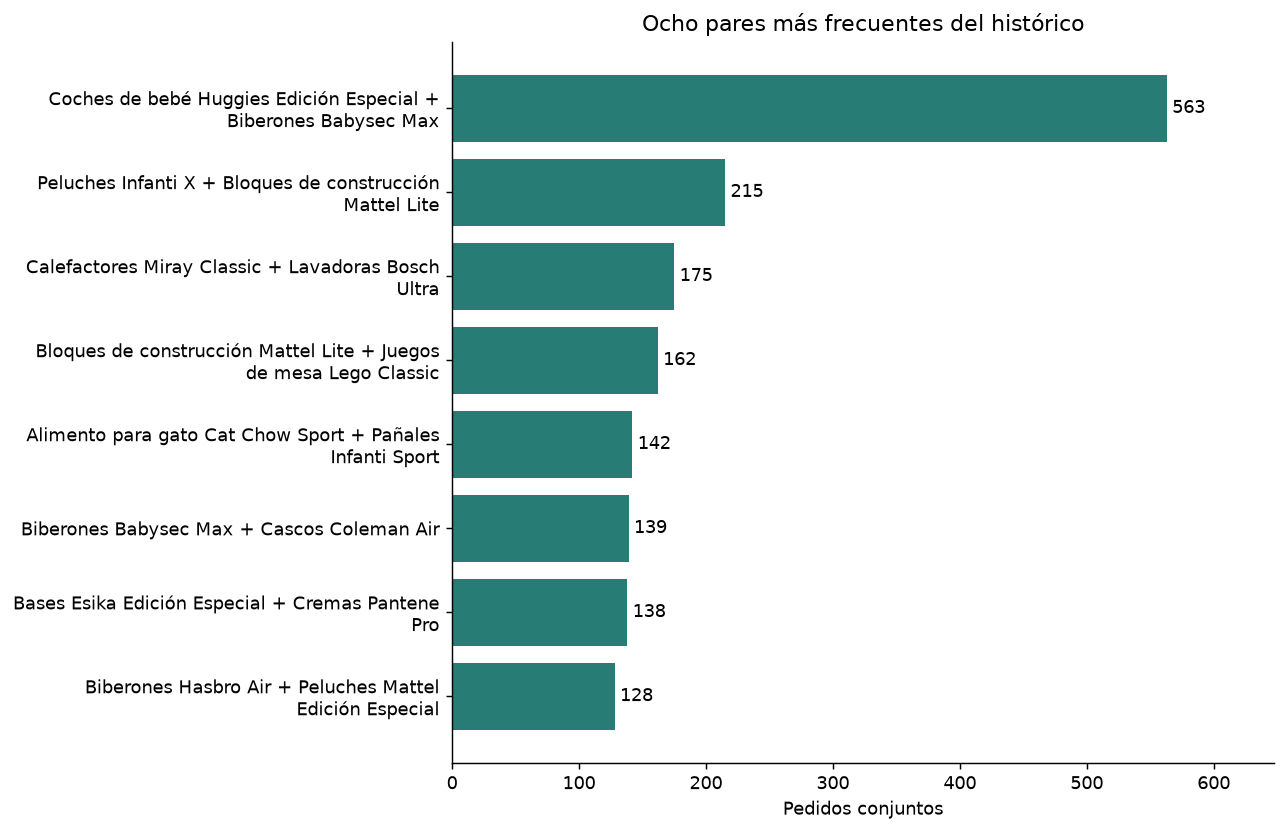

In [14]:
fig, ax = plt.subplots(figsize=(10,6.5))
bars = ax.barh(labels[::-1], top.pedidos_juntos.iloc[::-1], color='#287C76')
ax.bar_label(bars, padding=3)
ax.set(xlabel='Pedidos conjuntos', title='Ocho pares más frecuentes del histórico')
ax.set_xlim(0, top.pedidos_juntos.max()*1.15)
fig.tight_layout(); fig.savefig(OUTPUT/'grafico_cocompras.png', bbox_inches='tight'); plt.show()

In [15]:
with engine.connect() as connection:
    orders,clients,items,shipments,reviews,vendors = load_frames(connection)
valid = clean_shipments(shipments)
courier_summary = valid.groupby('courier').agg(envios=('id_envio','size'), dias=('entrega_dias','mean'), retraso=('retrasado','mean')).reset_index()
courier_summary['retraso_pct'] = courier_summary.pop('retraso')*100
display(courier_summary.round(2))

,courier,envios,dias,retraso_pct
0,99minutos,12625,1.27,12.23
1,Chazki,18623,1.27,11.94
2,Marvisur,4306,4.26,48.91
3,Olva Courier,19974,3.26,34.01
4,Savar Express,10863,2.94,37.34
5,Serpost,4403,6.60,84.28
6,Shalom,9893,3.93,32.12
7,Urbano Express,15601,2.91,36.97


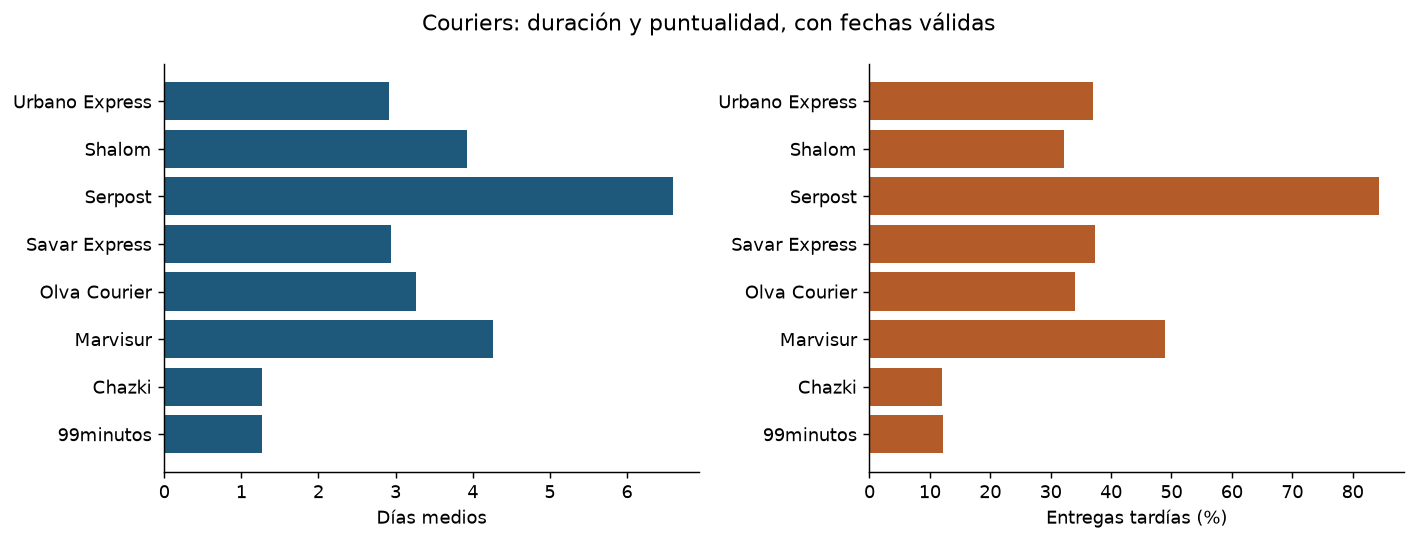

In [16]:
fig, axes = plt.subplots(1,2,figsize=(11,4.2))
axes[0].barh(courier_summary.courier, courier_summary.dias, color='#1E597C'); axes[0].set_xlabel('Días medios')
axes[1].barh(courier_summary.courier, courier_summary.retraso_pct, color='#B45C29'); axes[1].set_xlabel('Entregas tardías (%)')
fig.suptitle('Couriers: duración y puntualidad, con fechas válidas')
fig.tight_layout(); fig.savefig(OUTPUT/'grafico_couriers.png', bbox_inches='tight'); plt.show()
courier_summary.to_csv(OUTPUT/'resumen_couriers.csv', index=False)

In [17]:
diagnostic = reports['diagnostico']
display(diagnostic[['id_vendedor','razon_social','ventas_brutas','estrellas_promedio','retraso_pct']].head(8))
display(pd.DataFrame([bundle['criteria']]))
vendors_frame = reports['vendedores']
eligible = vendors_frame[(vendors_frame.pedidos>=10)&vendors_frame.estrellas_promedio.notna()].dropna(subset=['retraso_pct'])

,id_vendedor,razon_social,ventas_brutas,estrellas_promedio,retraso_pct
57,58,Grupo Rímac S.A.C. 57,"2,021,369.35",2.99,94.84
385,386,Negocios Titicaca S.A.C.,"1,206,974.27",2.88,95.06
696,697,Negocios Moche S.A.C.,"426,429.31",2.66,96.53
28,29,Negocios Cóndor S.A.C.,"319,195.22",2.79,97.24
174,175,Grupo Misti S.A. 174,"280,499.17",2.75,94.90
160,161,Comercial Norte S.A.C. 160,"256,926.04",2.97,94.48
558,559,Negocios del Sur S.A.C. 558,"183,569.71",2.74,94.48
113,114,Distribuidora Moche S.A. 113,"162,727.45",3.10,96.10


,ventas_altas_desde,minimo_pedidos,maximo_estrellas,minimo_retraso_pct,correlacion_estrellas_retrasos,vendedores_correlacion
0,"42,644.91",10,3.50,25,-0.75,393


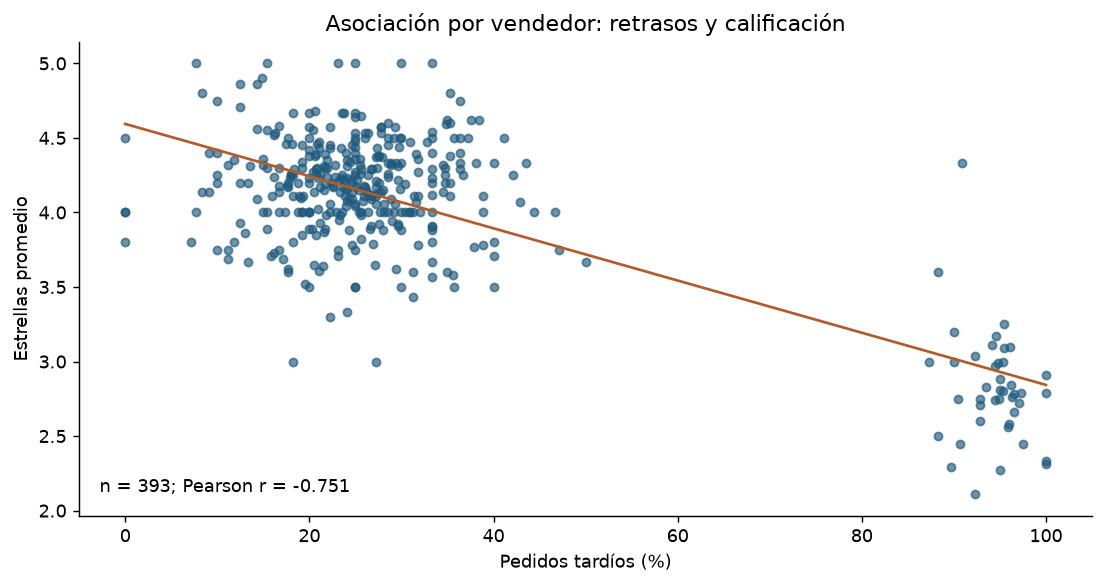

14 vendedores cumplen los tres criterios. La asociación no demuestra causalidad.


In [18]:
fig, ax = plt.subplots(figsize=(8.6,4.6))
ax.scatter(eligible.retraso_pct,eligible.estrellas_promedio,s=20,alpha=.65,color='#1E597C')
coefficient = np.polyfit(eligible.retraso_pct.to_numpy(dtype=float),eligible.estrellas_promedio.to_numpy(dtype=float),1)
horizontal = np.linspace(0,100,100); ax.plot(horizontal,np.polyval(coefficient,horizontal),color='#B45C29',lw=1.5)
ax.set(xlabel='Pedidos tardíos (%)',ylabel='Estrellas promedio',title='Asociación por vendedor: retrasos y calificación')
ax.text(.02,.05,f"n = {len(eligible)}; Pearson r = {bundle['criteria']['correlacion_estrellas_retrasos']:.3f}",transform=ax.transAxes)
fig.tight_layout(); fig.savefig(OUTPUT/'grafico_reputacion.png', bbox_inches='tight'); plt.show()
print('14 vendedores cumplen los tres criterios. La asociación no demuestra causalidad.')

## 4. Análisis SQL adicionales
Inactividad adaptada a la cadencia del cliente, concentración por categoría, riesgo de courier y afinidad mediante canastas deduplicadas.

In [19]:
advanced = pd.DataFrame([{'reporte':name, 'filas':len(reports[name])}
    for name in ['clientes_inactivos','participacion_categorias','riesgo_courier','afinidad_sql']])
display(advanced)
display(reports['riesgo_courier'].head(6))
print('Los intervalos de Wilson son aproximados y presuponen observaciones independientes.')

,reporte,filas
0,clientes_inactivos,4023
1,participacion_categorias,75
2,riesgo_courier,128
3,afinidad_sql,100


,id_courier,courier,departamento,envios,entrega_dias,dispersion_dias,retraso_pct,limite_inferior_95_pct,limite_superior_95_pct,posicion_en_departamento
0,2,Shalom,Amazonas,86,7.30,2.71,27.91,19.53,38.18,1
1,1,Olva Courier,Amazonas,74,7.75,2.43,33.78,24.04,45.12,2
2,3,Urbano Express,Amazonas,38,8.41,3.54,36.84,23.38,52.71,3
3,2,Shalom,Áncash,318,3.91,1.52,16.98,13.25,21.50,1
4,8,Marvisur,Áncash,107,4.40,1.63,22.43,15.56,31.21,2
5,1,Olva Courier,Áncash,307,4.60,1.63,28.01,23.28,33.28,3


Los intervalos de Wilson son aproximados y presuponen observaciones independientes.
